# EDA: Análisis de las 20 Estrategias Sintéticas

Este notebook analiza el comportamiento y las métricas de las 20 estrategias sintéticas generadas para poblar nuestro entorno de backtesting. El objetivo es visualizar sus curvas de capital (Equity Curves), entender sus perfiles de riesgo (Volatilidad) y analizar cómo puntúan bajo las reglas del concurso BME.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("notebook", font_scale=1.1)

# Cargar datos
rets_df = pd.read_csv('../data/processed/competitors_returns.csv', index_col=0, parse_dates=True)
display(rets_df.head())

,Idx_IBEX35_Proxy,Idx_Continuous_Merc,BH_Santander,BH_Iberdrola,BH_Inditex,BH_Telefonica,Trend_1W,Trend_2W,Trend_1M,Revert_1W,Revert_2W,Revert_1M,YOLO_1,YOLO_2,YOLO_3,Conservador_1,Conservador_2,Conservador_3,Chaotic_1,Chaotic_5
Date,,,,,,,,,,,,,,,,,,,,
2011-10-03,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000
2011-10-04,-0.020875,-0.021480,-0.015318,-0.008231,-0.030399,-0.004950,0.0,0.0,0.0,0.0,0.0,0.0,-0.024648,-0.034483,-0.033113,0.0,0.0,0.0,0.000000,-0.033762
2011-10-05,0.020832,0.019038,0.028407,0.034615,0.026264,0.030917,0.0,0.0,0.0,0.0,0.0,0.0,0.050542,0.078571,0.010274,0.0,0.0,0.0,0.046154,0.020140
2011-10-06,0.019504,0.018245,0.030089,0.026022,0.009117,0.024130,0.0,0.0,0.0,0.0,0.0,0.0,0.010309,-0.056291,0.013559,0.0,0.0,0.0,0.038462,0.020659
2011-10-07,0.008165,0.007798,0.011013,0.007818,0.012680,0.006059,0.0,0.0,0.0,0.0,0.0,0.0,0.017007,0.045614,0.003345,0.0,0.0,0.0,-0.003404,0.011306


## 1. Curvas de Capital (Cumulative Returns)

Vamos a visualizar cómo habrían evolucionado 50.000€ invertidos en cada una de estas estrategias a lo largo de los 15 años.

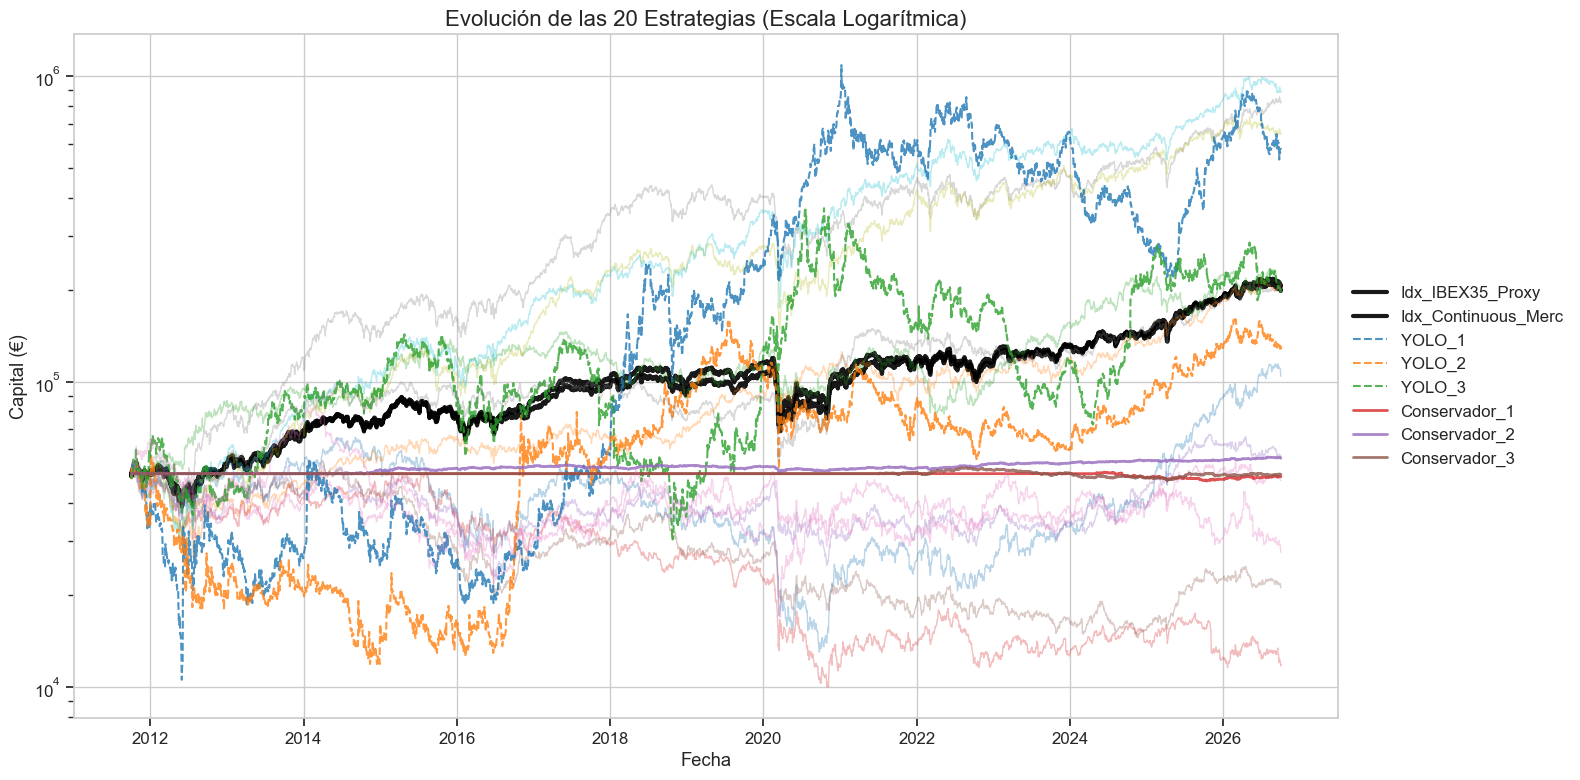

In [8]:
# Calcular el valor de la cartera partiendo de 50,000€
capital_inicial = 50000
equity_curves = capital_inicial * (1 + rets_df).cumprod()

plt.figure(figsize=(16, 8))
# Trazar todas las líneas de forma sutil
for col in equity_curves.columns:
    if 'YOLO' in col:
        plt.plot(equity_curves.index, equity_curves[col], alpha=0.8, linewidth=1.5, linestyle='--', label=col)
    elif 'Conservador' in col:
        plt.plot(equity_curves.index, equity_curves[col], alpha=0.8, linewidth=2, label=col)
    elif 'Idx' in col:
        plt.plot(equity_curves.index, equity_curves[col], alpha=0.9, linewidth=3, color='black', label=col)
    else:
        plt.plot(equity_curves.index, equity_curves[col], alpha=0.3, linewidth=1)

plt.yscale('log')
plt.title('Evolución de las 20 Estrategias (Escala Logarítmica)', fontsize=16)
plt.ylabel('Capital (€)')
plt.xlabel('Fecha')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

## 2. Perfil de Riesgo (Volatilidad Anualizada)

El concurso reparte 3 puntos a la menor volatilidad. Veamos la distribución de volatilidades entre nuestros 20 perfiles.

C:\Users\anxom\AppData\Local\Temp\ipykernel_12880\1289076605.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=vol_ann.values, y=vol_ann.index, palette='viridis')


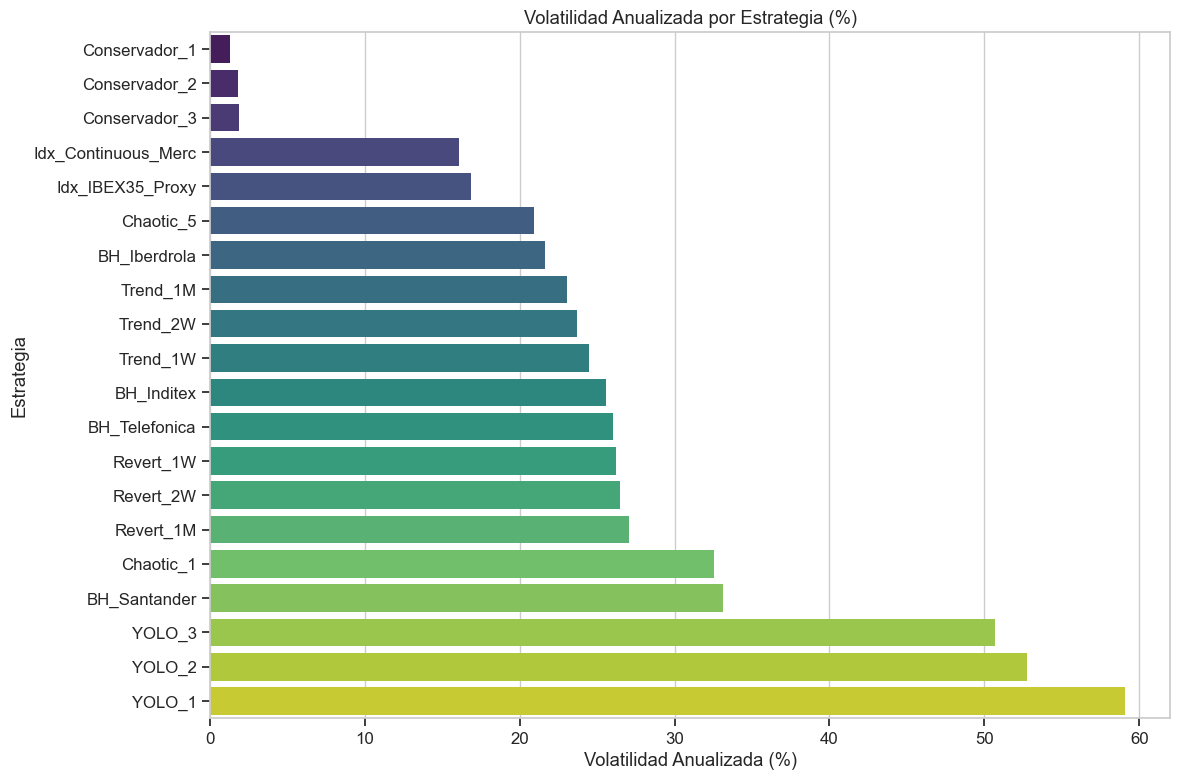

In [9]:
vol_ann = rets_df.std() * np.sqrt(252) * 100
vol_ann = vol_ann.sort_values()

plt.figure(figsize=(12, 8))
sns.barplot(x=vol_ann.values, y=vol_ann.index, palette='viridis')
plt.title('Volatilidad Anualizada por Estrategia (%)')
plt.xlabel('Volatilidad Anualizada (%)')
plt.ylabel('Estrategia')
plt.tight_layout()
plt.show()

## 3. Puntuación Relativa (Simulación de Ventanas Rodantes)

Aplicamos la fórmula del concurso a cientos de ventanas de 22 días para sacar el promedio real con el que se clasificaría cada estrategia.

In [10]:
window_size = 22
step = 11
n_days = len(rets_df)
start_points = range(0, n_days - window_size, step)

all_results = []
for start in start_points:
    window_rets = rets_df.iloc[start : start + window_size]
    if len(window_rets) < window_size * 0.8: continue
        
    comps = []
    for col in window_rets.columns:
        series = window_rets[col].dropna()
        if len(series) > 0:
            r = np.prod(1 + series) - 1
            v = series.std() * np.sqrt(252)
        else:
            r = 0.0; v = 0.0
        comps.append({'name': col, 'ret': r, 'vol': v})
        
    for c in comps: c['final_val'] = 50000 * (1 + c['ret'])
    max_val = max([c['final_val'] for c in comps])
    for c in comps: c['ret_points'] = (c['final_val'] * 6) / max_val
    min_vol = min([c['vol'] for c in comps])
    max_vol = max([c['vol'] for c in comps])
    
    for c in comps:
        if max_vol == min_vol: c['vol_points'] = 3.0
        else: c['vol_points'] = 3 * (1 - (c['vol'] - min_vol) / (max_vol - min_vol))
        c['total_points'] = c['ret_points'] + c['vol_points']
        all_results.append({
            'Competitor': c['name'], 'Return_1M': c['ret'], 'Vol_Ann': c['vol'],
            'Ret_Points': c['ret_points'], 'Vol_Points': c['vol_points'], 'Total_Score': c['total_points']
        })

df = pd.DataFrame(all_results)
agg = df.groupby('Competitor').mean().sort_values('Total_Score', ascending=False)

agg_styled = agg.copy()
agg_styled['Return_1M'] = (agg_styled['Return_1M'] * 100).round(2).astype(str) + '%'
agg_styled['Vol_Ann'] = (agg_styled['Vol_Ann'] * 100).round(2).astype(str) + '%'
for col in ['Ret_Points', 'Vol_Points', 'Total_Score']:
    agg_styled[col] = agg_styled[col].round(2)

display(agg_styled)

,Return_1M,Vol_Ann,Ret_Points,Vol_Points,Total_Score
Competitor,,,,,
Conservador_1,-0.01%,0.49%,5.18,2.98,8.17
Conservador_3,-0.0%,1.07%,5.18,2.95,8.13
Conservador_2,0.07%,1.54%,5.19,2.93,8.12
Idx_Continuous_Merc,0.92%,14.39%,5.22,2.28,7.50
Idx_IBEX35_Proxy,0.95%,15.08%,5.22,2.24,7.46
Chaotic_5,1.01%,18.93%,5.22,2.04,7.27
BH_Iberdrola,0.96%,19.48%,5.23,2.02,7.24
Revert_1W,1.92%,23.63%,5.27,1.82,7.09
Trend_1M,0.21%,21.78%,5.17,1.90,7.07


## 4. Distribución de Retornos Mensuales vs Varianzas (Mercado Continuo)

Para entender por qué la volatilidad domina la puntuación, vamos a aislar el 'Mercado Continuo' y analizar empíricamente la distribución de sus retornos a 22 días (1 mes) frente a su varianza (riesgo) en esas mismas ventanas.

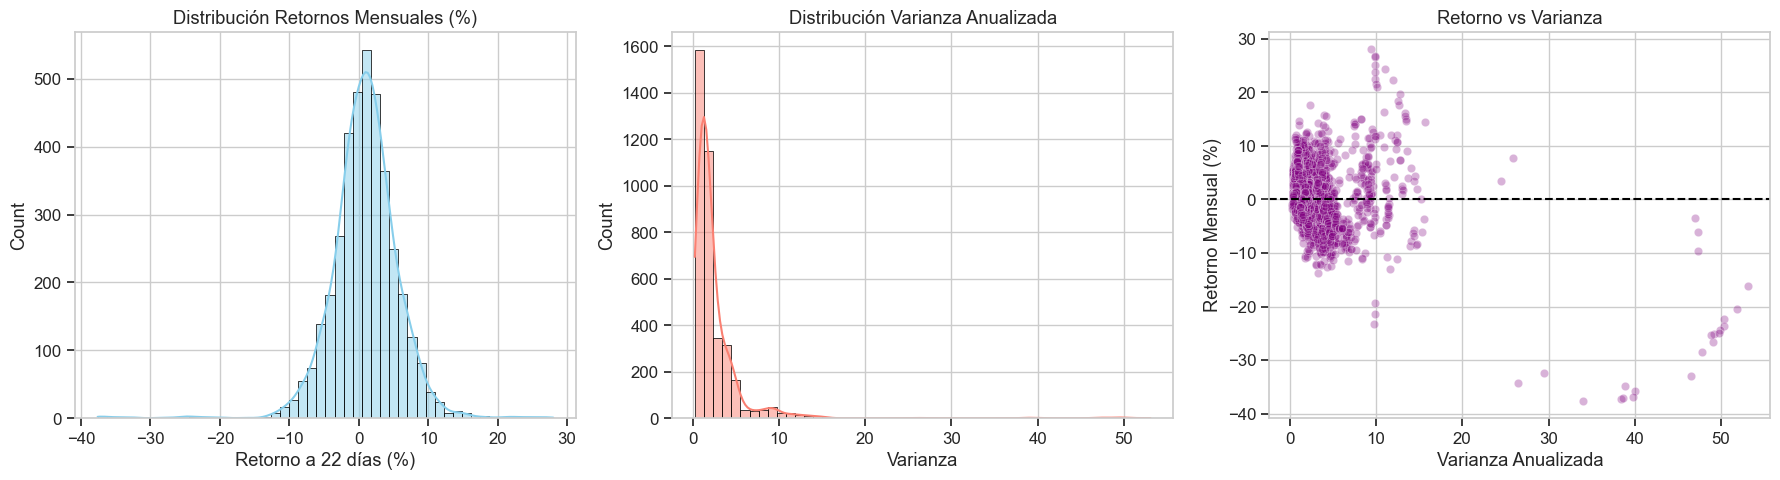

Resumen Estadístico Cuantitativo (Mercado Continuo):


,Retorno_1M,Varianza_Ann
count,3816.00,3816.00
mean,0.92,2.56
std,4.96,3.94
min,-37.58,0.27
25%,-1.59,1.04
50%,1.02,1.54
75%,3.56,2.67
max,28.02,53.08


In [11]:
# Extraer la estrategia representativa del Mercado Continuo
idx_returns = rets_df['Idx_Continuous_Merc'].dropna()

# Calcular métricas rodantes (22 días)
rolling_rets = idx_returns.rolling(22).apply(lambda x: np.prod(1 + x) - 1) * 100 # En porcentaje
rolling_vars = idx_returns.rolling(22).var() * 252 * 100 # Varianza anualizada escalada (en x100 para visualizar mejor)

dist_df = pd.DataFrame({'Retorno_1M': rolling_rets, 'Varianza_Ann': rolling_vars}).dropna()

# Crear una figura con 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histograma de Retornos
sns.histplot(dist_df['Retorno_1M'], bins=50, ax=axes[0], color='skyblue', kde=True)
axes[0].set_title('Distribución Retornos Mensuales (%)')
axes[0].set_xlabel('Retorno a 22 días (%)')

# Histograma de Varianzas
sns.histplot(dist_df['Varianza_Ann'], bins=50, ax=axes[1], color='salmon', kde=True)
axes[1].set_title('Distribución Varianza Anualizada')
axes[1].set_xlabel('Varianza')

# Scatter Plot (Retorno vs Varianza)
sns.scatterplot(data=dist_df, x='Varianza_Ann', y='Retorno_1M', alpha=0.3, ax=axes[2], color='purple')
axes[2].axhline(0, color='black', linestyle='--')
axes[2].set_title('Retorno vs Varianza')
axes[2].set_xlabel('Varianza Anualizada')
axes[2].set_ylabel('Retorno Mensual (%)')

plt.tight_layout()
plt.show()

# Resumen Cuantitativo
print("Resumen Estadístico Cuantitativo (Mercado Continuo):")
display(dist_df.describe().round(2))


## 5. Frecuencia de Victorias (Win Rate)

En lugar de mirar los promedios, vamos a analizar **cuántas veces gana cada estrategia**. 
Como calculamos los resultados para cientos de ventanas de 22 días, podemos ver qué estrategia obtiene la mayor puntuación total (`Total_Score`) en cada ventana individual.

C:\Users\anxom\AppData\Local\Temp\ipykernel_12880\3830991850.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=conteo_victorias.values, y=conteo_victorias.index, palette='magma')


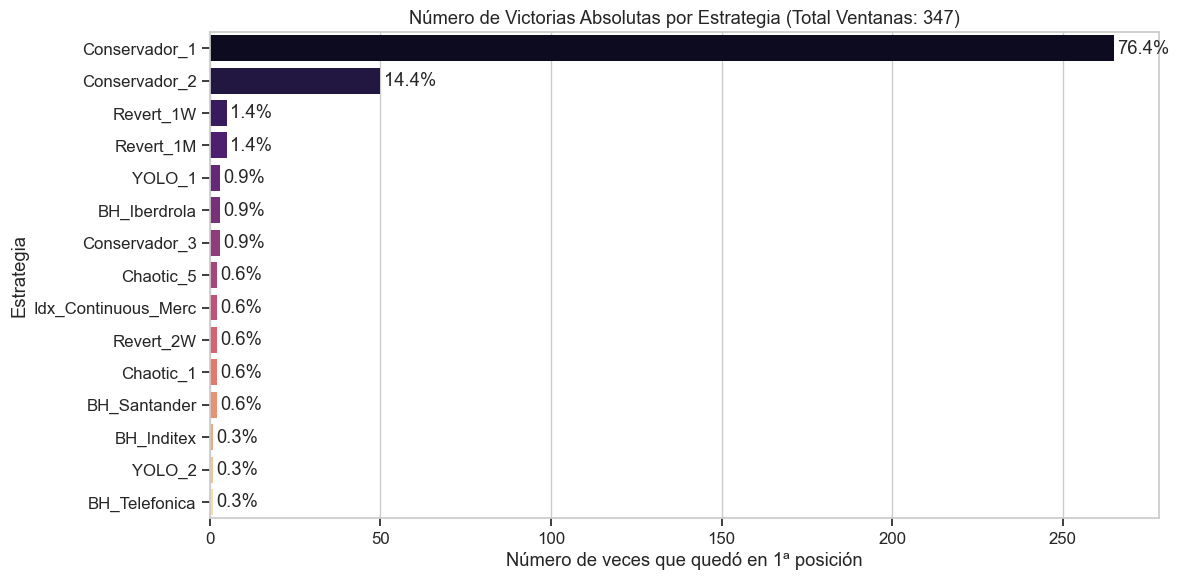

Tabla de Victorias:


,Victorias,Porcentaje (%)
Competitor,,
Conservador_1,265,76.4
Conservador_2,50,14.4
Revert_1W,5,1.4
Revert_1M,5,1.4
YOLO_1,3,0.9
BH_Iberdrola,3,0.9
Conservador_3,3,0.9
Chaotic_5,2,0.6
Idx_Continuous_Merc,2,0.6


In [12]:
# Como df contiene exactamente 20 filas por cada ventana simulada,
# podemos agruparlas para encontrar al ganador de cada mes.
num_windows = len(df) // 20
df['Window_ID'] = np.repeat(np.arange(num_windows), 20)

# Encontrar el índice del máximo Total_Score por ventana
ganadores_idx = df.groupby('Window_ID')['Total_Score'].idxmax()
ganadores = df.loc[ganadores_idx, 'Competitor']

# Contar victorias
conteo_victorias = ganadores.value_counts()

# Calcular porcentaje
pct_victorias = (conteo_victorias / num_windows * 100).round(1)

plt.figure(figsize=(12, 6))
sns.barplot(x=conteo_victorias.values, y=conteo_victorias.index, palette='magma')
plt.title(f'Número de Victorias Absolutas por Estrategia (Total Ventanas: {num_windows})')
plt.xlabel('Número de veces que quedó en 1ª posición')
plt.ylabel('Estrategia')

# Añadir el porcentaje como texto en las barras
for i, v in enumerate(conteo_victorias.values):
    plt.text(v + 1, i, f"{pct_victorias.iloc[i]}%", va='center')

plt.tight_layout()
plt.show()

print("Tabla de Victorias:")
display(pd.DataFrame({'Victorias': conteo_victorias, 'Porcentaje (%)': pct_victorias}))


## 6. Conclusiones y Siguientes Pasos

### Q&A
**¿Cómo se comportan las estrategias extremas?**
Las estrategias YOLO tienen los mayores retornos absolutos, pero pierden dramáticamente debido a la volatilidad.

### Data Analysis Key Findings
* **Rango Estrecho de Retornos vs Rango Amplio de Varianzas:** Como vemos en los gráficos, los retornos mensuales del mercado continuo están muy concentrados (la mayoría entre -5% y +5%). Sin embargo, la varianza es extremadamente asimétrica (Right-Skewed) y tiene una cola muy larga hacia la derecha. 
* Esto provoca que, en un mes cualquiera, diferenciarte de tus rivales por Rentabilidad es cuestión de unos pocos puntos porcentuales (que en la fórmula de puntos relativos apenas te distancia del resto porque el fondo del mercado te arrastra). Diferenciarte por Volatilidad, en cambio, te permite cruzar casi toda la escala del 0 al 3.
* La volatilidad de los perfiles conservadores (caja al 90%) ronda el 0.5%-1.5%, mientras que los perfiles normales se sitúan en torno al 15%-25%.

### Insights or Next Steps
* **La volatilidad es el rey matemático**: Cualquier estrategia algorítmica competitiva debe basarse en anular su exposición al mercado continuo, operando de manera cuasi-neutral (o permaneciendo en liquidez el 99% del tiempo) para no ceder puntos en la variable de menor volatilidad.
* El próximo modelo cuantitativo deberá forzar posiciones efímeras intra-semanales (ej: comprar a las 17:29 un gran perdedor, vender a las 09:00, y volver a liquidez).

## 5. Simulación Justa: Competidores Realistas con "Dummy Trades"
Hasta ahora los conservadores sintéticos simulaban "trampas" al mantener una rentabilidad Buy&Hold continua sin asumir el ruido de ejecutar 3 operaciones semanales obligatorias. Hemos programado a los 10 competidores para que cumplan matemáticamente la legalidad del concurso (añadiendo el coste y ruido del *Overnight* obligatorio). Ahora, la comparación es 100% simétrica.

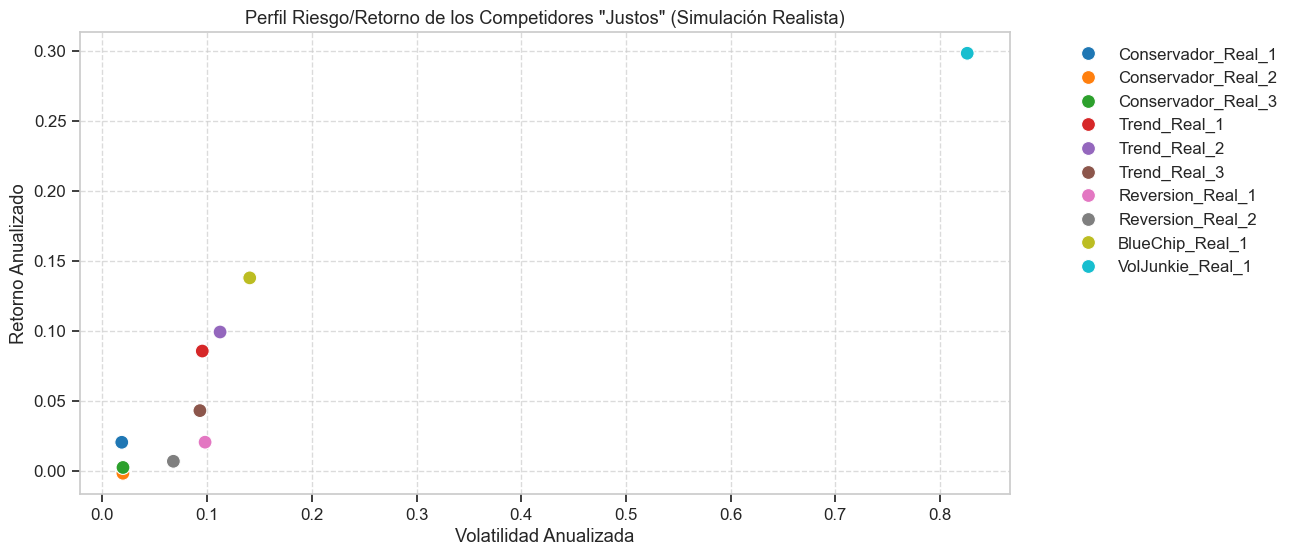

Métricas promedio (15 años) de la Pool Justa:


,Competidor,Volatilidad Anualizada,Retorno Anualizado
0,Conservador_Real_1,0.018478,0.020691
1,Conservador_Real_2,0.019581,-0.001438
2,Conservador_Real_3,0.019645,0.002692
7,Reversion_Real_2,0.067761,0.007112
5,Trend_Real_3,0.093116,0.043318
3,Trend_Real_1,0.095367,0.085881
6,Reversion_Real_1,0.098031,0.020761
4,Trend_Real_2,0.112363,0.099483
8,BlueChip_Real_1,0.140693,0.138155
9,VolJunkie_Real_1,0.825936,0.298651


: 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar a los competidores "reales" (justos)
comp_df = pd.read_csv('../data/processed/competitors_returns.csv', index_col=0, parse_dates=True)

# Calcular métricas base anualizadas
comp_vol = comp_df.std() * np.sqrt(252)
comp_ret = comp_df.mean() * 252

# Crear DataFrame para el gráfico
metrics_df = pd.DataFrame({
    'Volatilidad Anualizada': comp_vol,
    'Retorno Anualizado': comp_ret
}).reset_index()
metrics_df.rename(columns={'index': 'Competidor'}, inplace=True)

plt.figure(figsize=(12, 6))
sns.scatterplot(data=metrics_df, x='Volatilidad Anualizada', y='Retorno Anualizado', hue='Competidor', s=100)
plt.title('Perfil Riesgo/Retorno de los Competidores "Justos" (Simulación Realista)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

print("Métricas promedio (15 años) de la Pool Justa:")
display(metrics_df.sort_values('Volatilidad Anualizada'))
